# Read file

In [25]:
import copy
import gzip
import random
import struct
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import DataLoader, Subset, TensorDataset, random_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

SEED = 42
FAST_MODE = True            # False = full 48k train + 6k validation, with 6k held out for test
EPOCHS = 3 if FAST_MODE else 6
TRAIN_LIMIT = 12_000 if FAST_MODE else None
VAL_LIMIT = 3_000 if FAST_MODE else None
BATCH_SIZE = 128
LEARNING_RATE = 1e-3

# Original folder from ML HW8; edit if your .gz files are stored elsewhere.
DATA_DIR = Path('/Users/kellyt/Documents/ml/HW8/MNISTdata')
IMAGE_GZ = DATA_DIR / 'train-images-idx3-ubyte.gz'
LABEL_GZ = DATA_DIR / 'train-labels-idx1-ubyte.gz'


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)
if torch.cuda.is_available():
    device = torch.device('cuda')
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')

print('PyTorch:', torch.__version__)
print('Device:', device)
print('Mode:', 'QUICK' if FAST_MODE else 'FULL', '| epochs per model:', EPOCHS)


PyTorch: 2.8.0
Device: mps
Mode: QUICK | epochs per model: 3


In [27]:
def read_mnist_images_gz(path):
    """Read MNIST IDX image data from a gzip file, returning (N, H, W) uint8."""
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f'Missing MNIST image file: {path}')
    with gzip.open(path, 'rb') as f:
        magic, count, rows, cols = struct.unpack('>IIII', f.read(16))
        if magic != 2051:
            raise ValueError(f'Invalid image IDX magic number {magic}; expected 2051')
        pixels = np.frombuffer(f.read(), dtype=np.uint8).copy()
    if pixels.size != count * rows * cols:
        raise ValueError(f'Expected {count * rows * cols} pixels; got {pixels.size}')
    return pixels.reshape(count, rows, cols)


def read_mnist_labels_gz(path):
    """Read MNIST IDX labels from a gzip file, returning (N,) uint8."""
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f'Missing MNIST label file: {path}')
    with gzip.open(path, 'rb') as f:
        magic, count = struct.unpack('>II', f.read(8))
        if magic != 2049:
            raise ValueError(f'Invalid label IDX magic number {magic}; expected 2049')
        labels = np.frombuffer(f.read(), dtype=np.uint8).copy()
    if labels.size != count:
        raise ValueError(f'Expected {count} labels; got {labels.size}')
    return labels


images = read_mnist_images_gz(IMAGE_GZ)  # Shape: (60000, 28, 28)
labels = read_mnist_labels_gz(LABEL_GZ)  # Shape: (60000,)
assert len(images) == len(labels), 'Number of images and labels must match'
assert images.shape[1:] == (28, 28), f'Expected 28x28 MNIST images, got {images.shape[1:]}'
print('Raw .gz images:', images.shape, '| labels:', labels.shape)


Raw .gz images: (60000, 28, 28) | labels: (60000,)


# Data Preparation

Training: 12000 | Validation: 3000 | Held-out test: 6000
Image tensor shape: (128, 1, 28, 28) | labels shape: (128,)


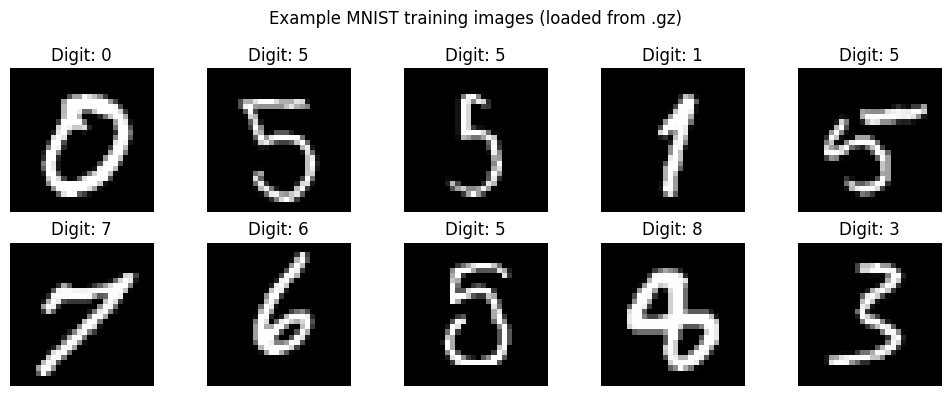

In [28]:
# CNNs need 4D image tensors (N, channels, height, width), not flattened (N, 784).
X_cnn = torch.from_numpy(images).unsqueeze(1).float() / 255.0  # (N, 1, 28, 28)
y_cnn = torch.from_numpy(labels.astype(np.int64))             # (N,)
full_dataset = TensorDataset(X_cnn, y_cnn)

# Use only the 60k HW8/HW9 training archive: train 48k, validation 6k, held-out test 6k.
# Splits are disjoint and reproducible. Held-out test is NOT the official MNIST test set.
assert len(full_dataset) == 60_000, f'Expected 60,000 training MNIST images; got {len(full_dataset)}'
train_dataset, val_dataset, test_dataset = random_split(
    full_dataset, [48_000, 6_000, 6_000],
    generator=torch.Generator().manual_seed(SEED)
)

if FAST_MODE:
    generator = torch.Generator().manual_seed(SEED)
    train_positions = torch.randperm(len(train_dataset), generator=generator)[:TRAIN_LIMIT].tolist()
    val_positions = torch.randperm(len(val_dataset), generator=generator)[:VAL_LIMIT].tolist()
    train_dataset = Subset(train_dataset, train_positions)
    val_dataset = Subset(val_dataset, val_positions)


def make_train_loader():
    # Reinitialize the shuffling generator for EACH model so comparisons use the same order.
    return DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                      generator=torch.Generator().manual_seed(SEED), num_workers=0)


val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print('Training:', len(train_dataset), '| Validation:', len(val_dataset), '| Held-out test:', len(test_dataset))
x_batch, y_batch = next(iter(make_train_loader()))
print('Image tensor shape:', tuple(x_batch.shape), '| labels shape:', tuple(y_batch.shape))
assert x_batch.ndim == 4 and x_batch.shape[1:] == (1, 28, 28)
assert y_batch.ndim == 1

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, image, label in zip(axes.ravel(), x_batch[:10], y_batch[:10]):
    ax.imshow(image.squeeze().numpy(), cmap='gray')
    ax.set_title(f'Digit: {label.item()}')
    ax.axis('off')
plt.suptitle('Example MNIST training images (loaded from .gz)')
plt.tight_layout()
plt.show()


# CNN Model

In [29]:
def make_activation(name):
    if name == 'relu':
        return nn.ReLU()
    if name == 'tanh':
        return nn.Tanh()
    if name == 'leaky_relu':
        return nn.LeakyReLU(negative_slope=0.1)
    if name == 'sigmoid':
        return nn.Sigmoid()
    raise ValueError(f'Unknown activation: {name}')


class MPSCompatibleAdaptiveAvgPool2d(nn.Module):
    """Exact adaptive-average pooling via fixed matrix multiplication.

    Unlike torch.nn.AdaptiveAvgPool2d, this works for non-divisible input/output
    sizes on the PyTorch MPS backend. Matrices are fixed, non-trainable buffers.
    """
    def __init__(self, input_size, output_size=(4, 4)):
        super().__init__()
        self.input_size = tuple(input_size)
        self.output_size = tuple(output_size)
        self.register_buffer(
            'row_weights', self._pool_weights(self.input_size[0], self.output_size[0]),
            persistent=False,
        )
        self.register_buffer(
            'column_weights', self._pool_weights(self.input_size[1], self.output_size[1]).T.contiguous(),
            persistent=False,
        )

    @staticmethod
    def _pool_weights(in_size, out_size):
        weights = torch.zeros(out_size, in_size)
        for i in range(out_size):
            start = i * in_size // out_size
            end = ((i + 1) * in_size + out_size - 1) // out_size
            weights[i, start:end] = 1.0 / (end - start)
        return weights

    def forward(self, x):
        if tuple(x.shape[-2:]) != self.input_size:
            raise ValueError(f'Expected spatial shape {self.input_size}, got {tuple(x.shape[-2:])}')
        # Two separable weighted averages; both forward and backward use MPS-safe matmul.
        row_weights = self.row_weights.to(dtype=x.dtype)
        column_weights = self.column_weights.to(dtype=x.dtype)
        return torch.matmul(torch.matmul(row_weights, x), column_weights)


class ConfigurableCNN(nn.Module):

    def __init__(self, conv_channels=(32, 64), pooling='max',
                 fc_layers=(128,), activation='relu'):
        super().__init__()
        if pooling not in {'max', 'avg', 'none'}:
            raise ValueError('pooling must be max, avg, or none')
        if not conv_channels:
            raise ValueError('conv_channels cannot be empty')

        conv_blocks = []
        in_channels = 1  # MNIST is grayscale
        spatial_size = 28  # Track feature-map side length for fixed-size MPS-safe pooling
        for layer_index, out_channels in enumerate(conv_channels):
            conv_blocks += [
                nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=1, padding=1),
                make_activation(activation),
            ]
            # Pool after the first two blocks, if requested.
            if pooling != 'none' and layer_index < 2:
                if pooling == 'max':
                    conv_blocks.append(nn.MaxPool2d(kernel_size=2))
                else:
                    conv_blocks.append(nn.AvgPool2d(kernel_size=2))
                spatial_size //= 2
            in_channels = out_channels

        self.features = nn.Sequential(*conv_blocks)
        # Fixed weighted averaging avoids the MPS non-divisible adaptive pooling error.
        # It retains the original 4x4 output and identical trainable parameter counts.
        self.final_spatial_pool = MPSCompatibleAdaptiveAvgPool2d(
            input_size=(spatial_size, spatial_size), output_size=(4, 4)
        )
        flattened_size = in_channels * 4 * 4

        classifier = [nn.Flatten()]
        previous_size = flattened_size
        for hidden_size in fc_layers:
            classifier += [nn.Linear(previous_size, hidden_size), make_activation(activation)]
            previous_size = hidden_size
        classifier.append(nn.Linear(previous_size, 10))
        self.classifier = nn.Sequential(*classifier)

    def forward(self, images):
        features = self.features(images)
        features = self.final_spatial_pool(features)
        return self.classifier(features)  # shape: [batch, 10] logits


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


baseline = ConfigurableCNN().to(device)
with torch.no_grad():
    dummy_logits = baseline(torch.zeros(4, 1, 28, 28, device=device))
print(baseline)
print('Example output:', tuple(dummy_logits.shape))
print('Trainable parameters:', f'{count_parameters(baseline):,}')
assert dummy_logits.shape == (4, 10)

ConfigurableCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (final_spatial_pool): MPSCompatibleAdaptiveAvgPool2d()
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1024, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Example output: (4, 10)
Trainable parameters: 151,306


## Experiments

In [31]:
EXPERIMENTS = {
    'Baseline':         dict(conv_channels=(32, 64), pooling='max',  fc_layers=(128,),     activation='relu'),
    'Shallow conv':     dict(conv_channels=(32,),    pooling='max',  fc_layers=(128,),     activation='relu'),
    'Deep conv':        dict(conv_channels=(32, 64, 96), pooling='max', fc_layers=(128,),  activation='relu'),
    'Average pool':     dict(conv_channels=(32, 64), pooling='avg',  fc_layers=(128,),     activation='relu'),
    'No intermed. pool':dict(conv_channels=(32, 64), pooling='none', fc_layers=(128,),     activation='relu'),
    'Small FC':         dict(conv_channels=(32, 64), pooling='max',  fc_layers=(32,),      activation='relu'),
    'Large FC':         dict(conv_channels=(32, 64), pooling='max',  fc_layers=(256,128),  activation='relu'),
    'Tanh':             dict(conv_channels=(32, 64), pooling='max',  fc_layers=(128,),     activation='tanh'),
    'Leaky ReLU':       dict(conv_channels=(32, 64), pooling='max',  fc_layers=(128,),     activation='leaky_relu'),
    'Sigmoid':       dict(conv_channels=(32, 64), pooling='max',  fc_layers=(128,),     activation='sigmoid'),
}

# Optional: run a subset of experiments while checking the notebook:
# EXPERIMENTS = {k: EXPERIMENTS[k] for k in ['Baseline', 'Average pool', 'Tanh']}

for name, cfg in EXPERIMENTS.items():
    model = ConfigurableCNN(**cfg)
    print(f'{name:<20} {count_parameters(model):>9,} parameters')

Baseline               151,306 parameters
Shallow conv            67,274 parameters
Deep conv              272,234 parameters
Average pool           151,306 parameters
No intermed. pool      151,306 parameters
Small FC                51,946 parameters
Large FC               315,402 parameters
Tanh                   151,306 parameters
Leaky ReLU             151,306 parameters
Sigmoid                151,306 parameters


## Training and Evaluation

In [ ]:
criterion = nn.CrossEntropyLoss()

def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += batch_size

    return total_loss / total, 100 * correct / total

@torch.no_grad()
def evaluate(model, loader, return_predictions=False):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_true, all_pred = [], []

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        loss = criterion(logits, labels)
        pred = logits.argmax(dim=1)

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        correct += (pred == labels).sum().item()
        total += batch_size

        if return_predictions:
            all_true.extend(labels.cpu().numpy().tolist())
            all_pred.extend(pred.cpu().numpy().tolist())

    stats = {'loss': total_loss / total, 'accuracy': 100 * correct / total}
    if return_predictions:
        stats['y_true'] = np.asarray(all_true)
        stats['y_pred'] = np.asarray(all_pred)
        stats['macro_f1'] = f1_score(stats['y_true'], stats['y_pred'], average='macro')
    return stats

def sync_device():
    # Ensure GPU work is complete before reading the clock.
    if device.type == 'cuda':
        torch.cuda.synchronize()
    elif device.type == 'mps' and hasattr(torch.mps, 'synchronize'):
        torch.mps.synchronize()

In [33]:
histories = {}
selected_weights = {}
training_rows = []

for name, config in EXPERIMENTS.items():
    print(f'\n=== {name} ===')
    set_seed(SEED)
    model = ConfigurableCNN(**config).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    train_loader = make_train_loader()

    best_val_accuracy = -1.0
    best_epoch = None
    best_state = None
    history = []

    sync_device()
    start = time.perf_counter()

    for epoch in range(1, EPOCHS + 1):
        train_loss, train_accuracy = train_one_epoch(model, train_loader, optimizer)
        val_stats = evaluate(model, val_loader)
        history.append({
            'epoch': epoch,
            'train_loss': train_loss,
            'train_accuracy': train_accuracy,
            'val_loss': val_stats['loss'],
            'val_accuracy': val_stats['accuracy'],
        })

        if val_stats['accuracy'] > best_val_accuracy:
            best_val_accuracy = val_stats['accuracy']
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())

        print(f'Epoch {epoch:>2}/{EPOCHS} | train loss {train_loss:.4f} | '
              f'train acc {train_accuracy:.2f}% | val loss {val_stats["loss"]:.4f} | '
              f'val acc {val_stats["accuracy"]:.2f}%')

    sync_device()
    elapsed = time.perf_counter() - start
    histories[name] = pd.DataFrame(history)
    selected_weights[name] = best_state
    training_rows.append({
        'Model': name,
        'Parameters': count_parameters(model),
        'Best epoch': best_epoch,
        'Val accuracy (%)': best_val_accuracy,
        'Val loss': histories[name].loc[best_epoch - 1, 'val_loss'],
        'Train accuracy (%)': histories[name].loc[best_epoch - 1, 'train_accuracy'],
        'Training time (s)': elapsed,
    })

results_df = pd.DataFrame(training_rows).sort_values('Val accuracy (%)', ascending=False).reset_index(drop=True)
best_name = str(results_df.loc[0, 'Model'])
print('\nBest configuration by VALIDATION accuracy:', best_name)
display(results_df.round(4))


=== Baseline ===
Epoch  1/3 | train loss 1.3169 | train acc 56.66% | val loss 0.7174 | val acc 76.17%
Epoch  2/3 | train loss 0.4472 | train acc 86.05% | val loss 0.3842 | val acc 88.27%
Epoch  3/3 | train loss 0.2747 | train acc 91.55% | val loss 0.2854 | val acc 91.03%

=== Shallow conv ===
Epoch  1/3 | train loss 1.7129 | train acc 52.18% | val loss 0.9962 | val acc 70.77%
Epoch  2/3 | train loss 0.7708 | train acc 75.78% | val loss 0.7034 | val acc 77.97%
Epoch  3/3 | train loss 0.5834 | train acc 81.40% | val loss 0.5752 | val acc 81.63%

=== Deep conv ===
Epoch  1/3 | train loss 1.2042 | train acc 58.27% | val loss 0.5887 | val acc 81.30%
Epoch  2/3 | train loss 0.3430 | train acc 89.07% | val loss 0.2596 | val acc 91.73%
Epoch  3/3 | train loss 0.1843 | train acc 94.53% | val loss 0.1833 | val acc 94.47%

=== Average pool ===
Epoch  1/3 | train loss 1.4513 | train acc 52.08% | val loss 0.8550 | val acc 72.10%
Epoch  2/3 | train loss 0.6074 | train acc 81.12% | val loss 0.5618 |

,Model,Parameters,Best epoch,Val accuracy (%),Val loss,Train accuracy (%),Training time (s)
0,Deep conv,272234,3,94.4667,0.1833,94.5250,3.2693
1,Tanh,151306,3,94.2333,0.1971,94.7417,1.5239
2,Leaky ReLU,151306,3,92.1667,0.2491,92.8833,1.8423
3,No intermed. pool,151306,3,92.1333,0.2662,91.7500,3.3260
4,Large FC,315402,3,91.1333,0.2873,90.4500,1.4251
5,Baseline,151306,3,91.0333,0.2854,91.5500,5.0538
6,Small FC,51946,3,88.5333,0.3687,89.1250,1.6321
7,Average pool,151306,3,88.0000,0.3939,87.0333,2.2833
8,Shallow conv,67274,3,81.6333,0.5752,81.4000,1.8721
9,Sigmoid,151306,3,17.7000,2.2126,14.2417,1.4688


## Validation

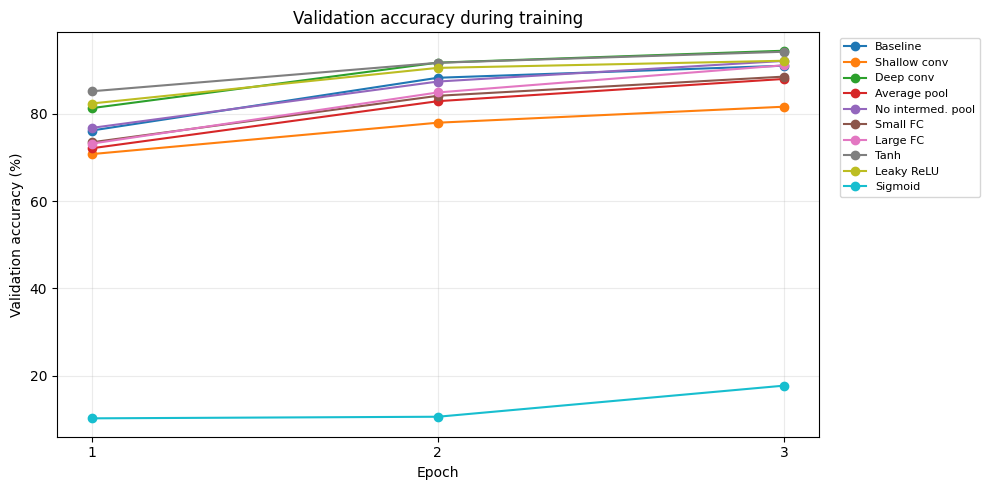

In [34]:
fig, ax = plt.subplots(figsize=(10, 5))
for name, hist in histories.items():
    ax.plot(hist['epoch'], hist['val_accuracy'], marker='o', label=name)
ax.set(title='Validation accuracy during training', xlabel='Epoch', ylabel='Validation accuracy (%)')
ax.set_xticks(range(1, EPOCHS + 1))
ax.grid(alpha=0.25)
ax.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

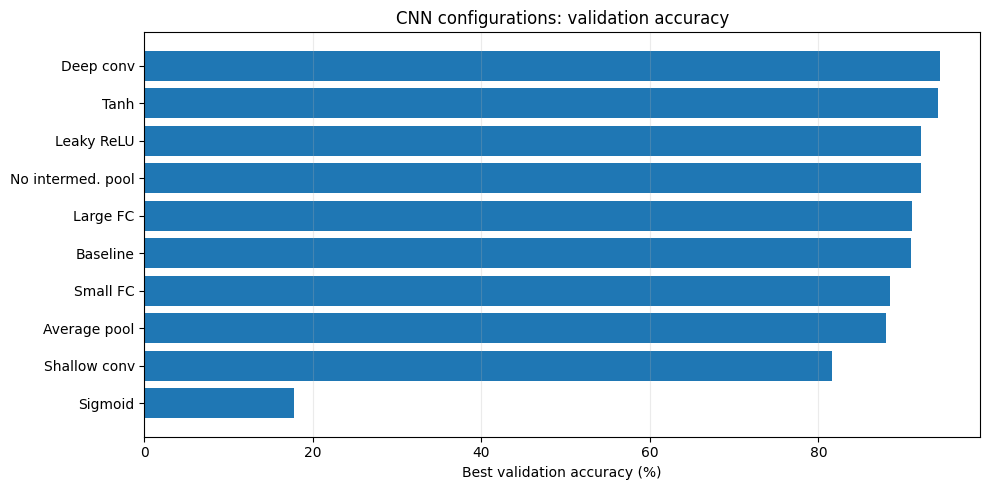

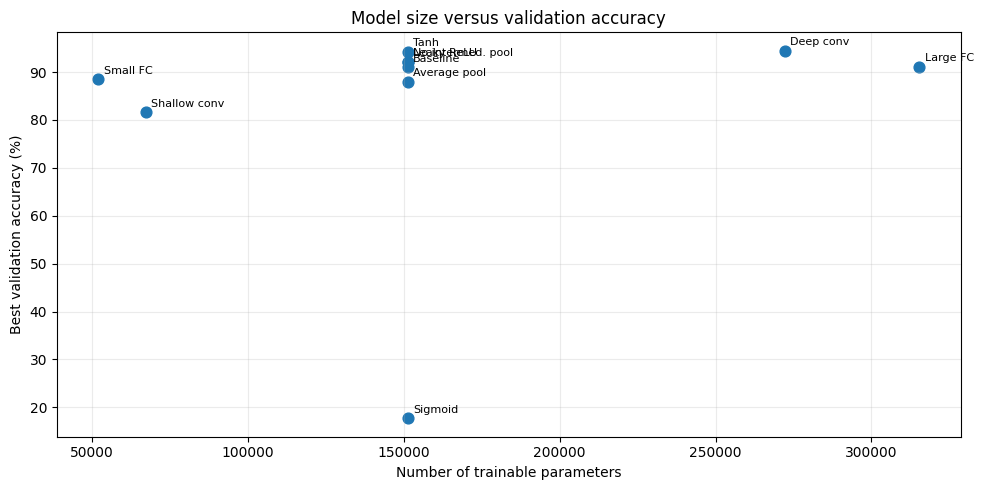

In [35]:
fig, ax = plt.subplots(figsize=(10, 5))
ordered = results_df.sort_values('Val accuracy (%)')
ax.barh(ordered['Model'], ordered['Val accuracy (%)'])
ax.set(xlabel='Best validation accuracy (%)', title='CNN configurations: validation accuracy')
ax.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(results_df['Parameters'], results_df['Val accuracy (%)'], s=60)
for _, row in results_df.iterrows():
    ax.annotate(row['Model'], (row['Parameters'], row['Val accuracy (%)']),
                xytext=(4, 4), textcoords='offset points', fontsize=8)
ax.set(xlabel='Number of trainable parameters', ylabel='Best validation accuracy (%)',
       title='Model size versus validation accuracy')
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Testing

VALIDATION-selected model: Deep conv


,Model,Parameters,Best epoch,Val accuracy (%),Val loss,Train accuracy (%),Training time (s),Test accuracy (%),Test macro F1,Test loss,Test evaluation time (s)
0,Deep conv,272234,3,94.4667,0.1833,94.5250,3.2693,94.6167,0.9457,0.1735,0.2608
1,Tanh,151306,3,94.2333,0.1971,94.7417,1.5239,94.9000,0.9484,0.1758,0.2625
2,Leaky ReLU,151306,3,92.1667,0.2491,92.8833,1.8423,93.0833,0.9302,0.2287,0.2346
3,No intermed. pool,151306,3,92.1333,0.2662,91.7500,3.3260,93.4333,0.9336,0.2269,0.2013
4,Large FC,315402,3,91.1333,0.2873,90.4500,1.4251,91.8333,0.9174,0.2653,0.2300
5,Baseline,151306,3,91.0333,0.2854,91.5500,5.0538,91.7500,0.9163,0.2599,0.2743
6,Small FC,51946,3,88.5333,0.3687,89.1250,1.6321,89.6667,0.8967,0.3336,0.1903
7,Average pool,151306,3,88.0000,0.3939,87.0333,2.2833,88.5333,0.8833,0.3677,0.2043
8,Shallow conv,67274,3,81.6333,0.5752,81.4000,1.8721,83.2333,0.8297,0.5341,0.2061
9,Sigmoid,151306,3,17.7000,2.2126,14.2417,1.4688,18.1833,0.0735,2.2090,0.2457


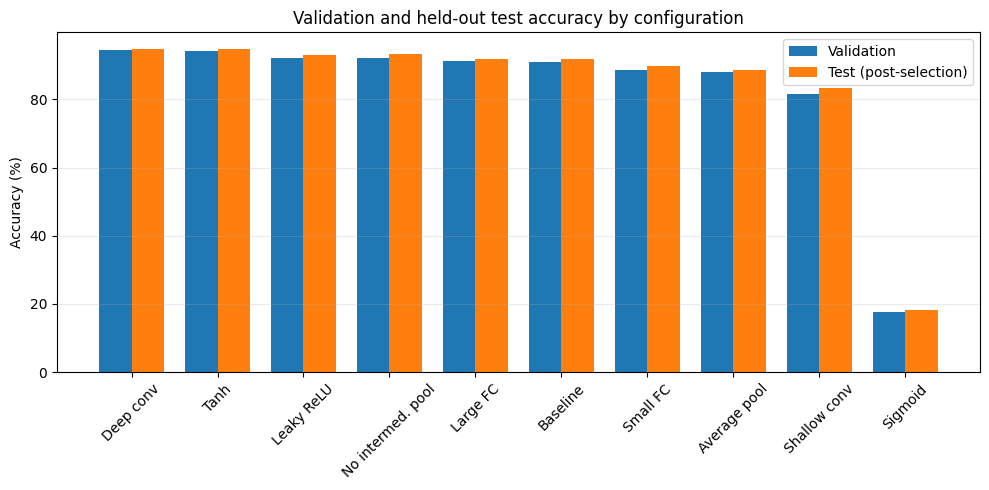

In [36]:
test_rows = []

for name, config in EXPERIMENTS.items():
    model = ConfigurableCNN(**config).to(device)
    model.load_state_dict(selected_weights[name])
    sync_device()
    start = time.perf_counter()
    stats = evaluate(model, test_loader, return_predictions=True)
    sync_device()
    elapsed = time.perf_counter() - start
    test_rows.append({
        'Model': name,
        'Test accuracy (%)': stats['accuracy'],
        'Test macro F1': stats['macro_f1'],
        'Test loss': stats['loss'],
        'Test evaluation time (s)': elapsed,
    })

final_df = results_df.merge(pd.DataFrame(test_rows), on='Model', how='left')
final_df = final_df.sort_values('Val accuracy (%)', ascending=False).reset_index(drop=True)
print('VALIDATION-selected model:', best_name)
display(final_df.round(4))

fig, ax = plt.subplots(figsize=(10, 5))
positions = np.arange(len(final_df))
width = 0.38
ax.bar(positions - width/2, final_df['Val accuracy (%)'], width=width, label='Validation')
ax.bar(positions + width/2, final_df['Test accuracy (%)'], width=width, label='Test (post-selection)')
ax.set(xticks=positions, xticklabels=final_df['Model'].tolist(),
       ylabel='Accuracy (%)', title='Validation and held-out test accuracy by configuration')
ax.tick_params(axis='x', rotation=45)
ax.legend()
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

## Best model

Selected CNN: Deep conv
Test accuracy: 94.62%
Test macro F1: 0.9457

Digit-wise classification report:
              precision    recall  f1-score   support

           0     0.9735    0.9468    0.9600       583
           1     0.9835    0.9820    0.9827       666
           2     0.9420    0.9322    0.9371       575
           3     0.9067    0.9534    0.9295       622
           4     0.9376    0.9581    0.9477       596
           5     0.9625    0.9402    0.9512       518
           6     0.9832    0.9607    0.9718       610
           7     0.9627    0.9436    0.9530       656
           8     0.8670    0.9715    0.9163       597
           9     0.9559    0.8648    0.9081       577

    accuracy                         0.9462      6000
   macro avg     0.9475    0.9453    0.9457      6000
weighted avg     0.9477    0.9462    0.9463      6000



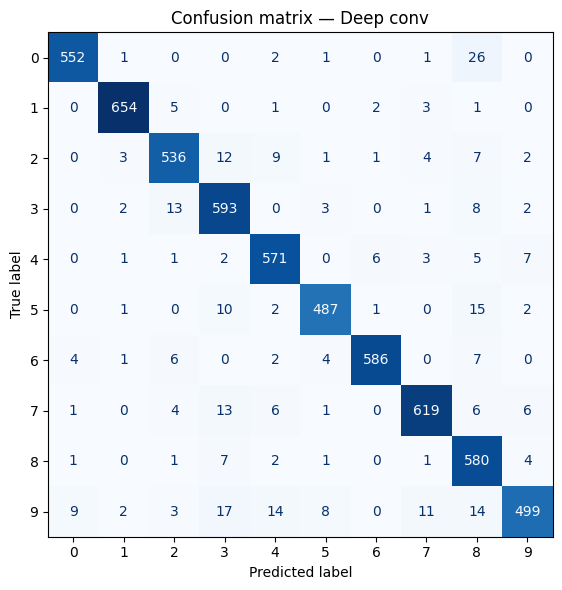

In [37]:
best_model = ConfigurableCNN(**EXPERIMENTS[best_name]).to(device)
best_model.load_state_dict(selected_weights[best_name])
best_stats = evaluate(best_model, test_loader, return_predictions=True)

y_true, y_pred = best_stats['y_true'], best_stats['y_pred']
print('Selected CNN:', best_name)
print('Test accuracy:', f'{best_stats["accuracy"]:.2f}%')
print('Test macro F1:', f'{best_stats["macro_f1"]:.4f}')
print('\nDigit-wise classification report:')
print(classification_report(y_true, y_pred, digits=4, zero_division=0))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, labels=list(range(10)), cmap='Blues', ax=ax,
    colorbar=False, values_format='d'
)
ax.set_title(f'Confusion matrix — {best_name}')
plt.tight_layout()
plt.show()

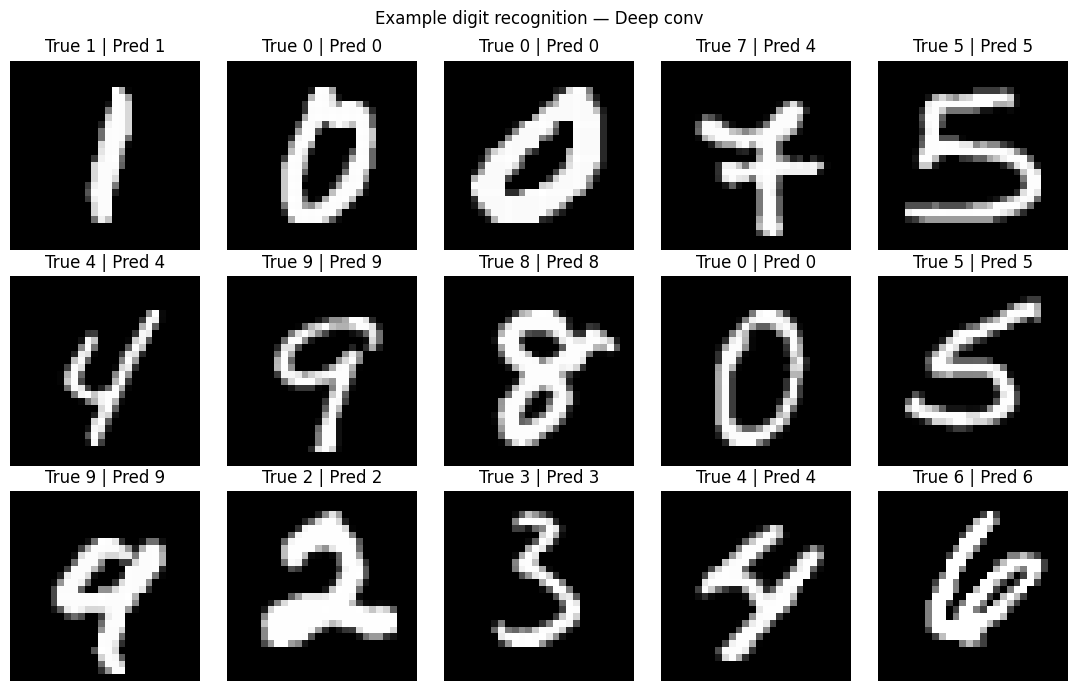

In [38]:
best_model.eval()
fig, axes = plt.subplots(3, 5, figsize=(11, 7))

with torch.no_grad():
    for i, ax in enumerate(axes.ravel()):
        image, true_label = test_dataset[i]
        logits = best_model(image.unsqueeze(0).to(device))
        predicted_label = logits.argmax(dim=1).item()
        ax.imshow(image.squeeze().numpy(), cmap='gray')
        ax.set_title(f'True {true_label} | Pred {predicted_label}')
        ax.axis('off')

plt.suptitle(f'Example digit recognition — {best_name}')
plt.tight_layout()
plt.show()